In [2]:
from pathlib import Path
import ast
import keyword
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE=42


In [4]:

from pathlib import Path
import pandas as pd

DATASET_PATH = Path("../leetcode-dataset/data/solutions.csv")

df = pd.read_csv(DATASET_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (2314, 2)


,leetcode_problem_id,python_code
0,01-matrix,import heapq\nfrom collections import defaultd...
1,1-bit-and-2-bit-characters,"class Solution:\n def isValid(self, bits, i..."
2,132-pattern,"class Solution:\n def find132pattern(self, ..."
3,2-keys-keyboard,from functools import lru_cache\n\nclass Solut...
4,24-game,"class Solution:\n def judgePoint24(self, ca..."


In [5]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check duplicate problem IDs
print("Duplicate problem IDs:",
      df["leetcode_problem_id"].duplicated().sum())

# Check code length
df["code_length"] = df["python_code"].fillna("").str.len()

print("\nCode length statistics:")
display(df["code_length"].describe())

Missing values:
leetcode_problem_id    0
python_code            0
dtype: int64

Duplicate rows: 0
Duplicate problem IDs: 0

Code length statistics:


count     2314.000000
mean       634.939067
std        739.361882
min         82.000000
25%        348.000000
50%        511.000000
75%        777.000000
max      29620.000000
Name: code_length, dtype: float64

In [6]:
import ast
import pandas as pd

# Function to analyse each Python program
def extract_features(code):
    try:
        # Convert Python code into an AST tree
        tree = ast.parse(code)

        # Count different elements present in the code
        functions = 0
        classes = 0
        loops = 0
        conditions = 0
        function_calls = 0
        imports = 0

        for node in ast.walk(tree):

            if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
                functions += 1

            elif isinstance(node, ast.ClassDef):
                classes += 1

            elif isinstance(node, (ast.For, ast.While)):
                loops += 1

            elif isinstance(node, ast.If):
                conditions += 1

            elif isinstance(node, ast.Call):
                function_calls += 1

            elif isinstance(node, (ast.Import, ast.ImportFrom)):
                imports += 1

        # Store all extracted features
        return {
            "syntax_valid": 1,
            "num_functions": functions,
            "num_classes": classes,
            "num_loops": loops,
            "num_conditionals": conditions,
            "num_function_calls": function_calls,
            "num_imports": imports,
            "num_lines": len(code.splitlines())
        }

    except SyntaxError:
        # Return invalid status if Python code has syntax errors
        return {"syntax_valid": 0}


# Apply the function to every Python solution
features = df["python_code"].apply(extract_features)

# Convert extracted features into a DataFrame
features_df = pd.DataFrame(features.tolist())

# Combine original data with extracted features
df_features = pd.concat([df, features_df], axis=1)

# Display the first five records
display(df_features.head())

,leetcode_problem_id,python_code,code_length,syntax_valid,num_functions,num_classes,num_loops,num_conditionals,num_function_calls,num_imports,num_lines
0,01-matrix,import heapq\nfrom collections import defaultd...,1304,1,1,1,5,6,16,2,35
1,1-bit-and-2-bit-characters,"class Solution:\n def isValid(self, bits, i...",716,1,2,1,0,8,5,0,25
2,132-pattern,"class Solution:\n def find132pattern(self, ...",390,1,1,1,2,1,6,0,12
3,2-keys-keyboard,from functools import lru_cache\n\nclass Solut...,410,1,1,1,0,3,6,1,14
4,24-game,"class Solution:\n def judgePoint24(self, ca...",1122,1,2,1,7,3,22,0,27


In [7]:
# Display basic statistics of extracted features

feature_columns = [
    "code_length",
    "num_functions",
    "num_classes",
    "num_loops",
    "num_conditionals",
    "num_function_calls",
    "num_imports",
    "num_lines"
]

display(df_features[feature_columns].describe().round(2))

,code_length,num_functions,num_classes,num_loops,num_conditionals,num_function_calls,num_imports,num_lines
count,2314.00,2314.00,2314.00,2314.00,2314.00,2314.00,2314.00,2314.00
mean,634.94,1.55,1.04,2.17,2.05,7.18,0.26,19.58
std,739.36,1.22,0.24,1.89,2.05,5.95,0.51,13.48
min,82.00,0.00,0.00,0.00,0.00,0.00,0.00,3.00
25%,348.00,1.00,1.00,1.00,1.00,3.00,0.00,11.00
50%,511.00,1.00,1.00,2.00,2.00,6.00,0.00,16.00
75%,777.00,2.00,1.00,3.00,3.00,9.00,0.00,24.00
max,29620.00,17.00,3.00,17.00,16.00,75.00,3.00,203.00


In [8]:
# Count valid and invalid Python solutions

syntax_counts = df_features["syntax_valid"].value_counts()

print("Valid solutions:", syntax_counts.get(1, 0))
print("Invalid solutions:", syntax_counts.get(0, 0))

Valid solutions: 2314
Invalid solutions: 0


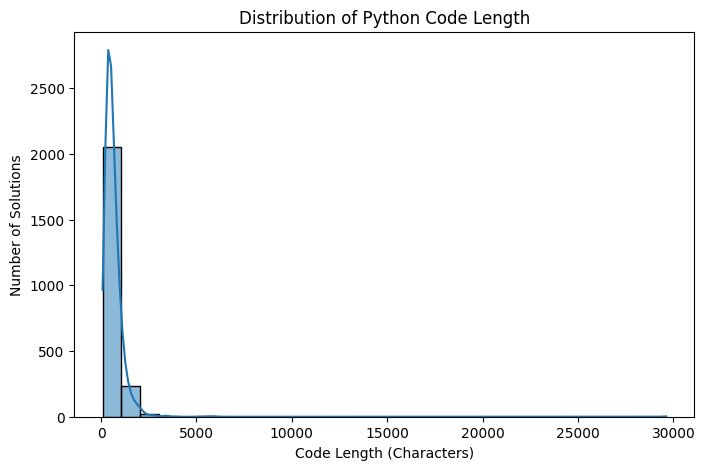

In [10]:


# Visualize distribution of Python code length
plt.figure(figsize=(8, 5))
sns.histplot(df_features["code_length"], bins=30, kde=True)

plt.title("Distribution of Python Code Length")
plt.xlabel("Code Length (Characters)")
plt.ylabel("Number of Solutions")
plt.show()

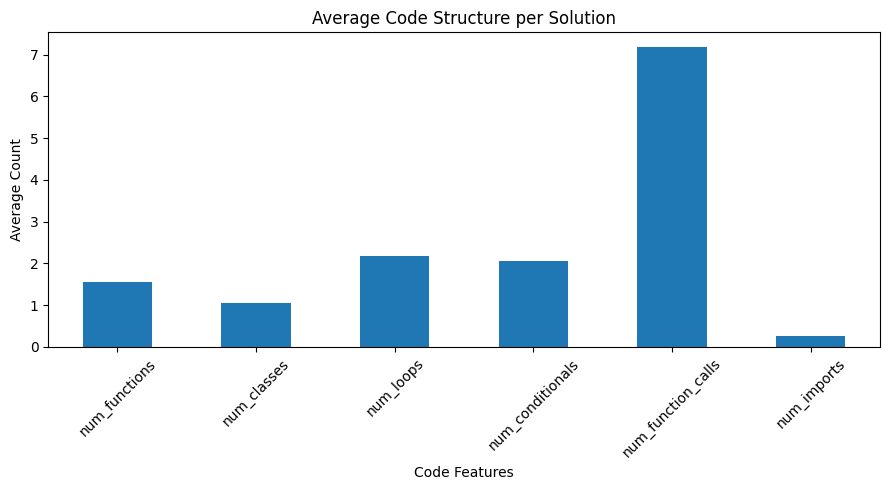

In [11]:
# Compare average number of structural elements
features_to_plot = [
    "num_functions",
    "num_classes",
    "num_loops",
    "num_conditionals",
    "num_function_calls",
    "num_imports"
]

average_features = df_features[features_to_plot].mean()

plt.figure(figsize=(9, 5))
average_features.plot(kind="bar")

plt.title("Average Code Structure per Solution")
plt.xlabel("Code Features")
plt.ylabel("Average Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

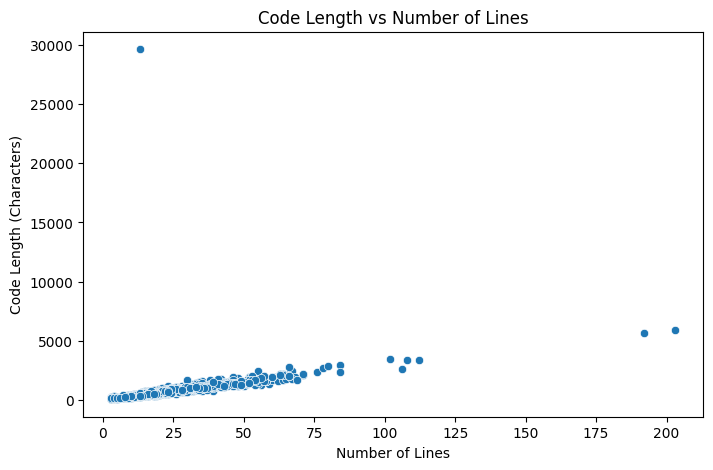

In [12]:
# Visualize the relationship between code length and lines
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_features,
    x="num_lines",
    y="code_length"
)

plt.title("Code Length vs Number of Lines")
plt.xlabel("Number of Lines")
plt.ylabel("Code Length (Characters)")
plt.show()

In [13]:
# Find the 10 longest Python solutions

longest_solutions = df_features.sort_values(
    by="code_length",
    ascending=False
).head(10)

display(
    longest_solutions[
        ["leetcode_problem_id", "code_length", "num_lines"]
    ]
)

,leetcode_problem_id,code_length,num_lines
2196,the-kth-factor-of-n,29620,13
891,k-divisible-elements-subarrays,5955,203
996,longest-duplicate-substring,5639,192
1471,minimum-number-of-valid-strings-to-form-target-i,3439,102
710,find-the-minimum-area-to-cover-all-ones-ii,3403,112
1094,maximize-count-of-distinct-primes-after-split,3354,108
196,checking-existence-of-edge-length-limited-path...,2930,84
938,largest-rectangle-in-histogram,2859,80
1384,minimum-cost-to-split-an-array,2760,66
625,find-minimum-diameter-after-merging-two-trees,2754,78


In [14]:
# Inspect the longest solution

longest_code = longest_solutions.iloc[0]["python_code"]

line_lengths = [
    len(line) for line in longest_code.splitlines()
]

print("Total lines:", len(line_lengths))
print("Longest individual line:", max(line_lengths))
print("Average line length:", round(sum(line_lengths) / len(line_lengths), 2))

Total lines: 13
Longest individual line: 29396
Average line length: 2277.54


In [15]:
from pathlib import Path

# Create the output folder if it does not exist
output_folder = Path("../reports")
output_folder.mkdir(parents=True, exist_ok=True)

# Save the extracted features
output_path = output_folder / "leetcode_features.csv"

df_features.to_csv(output_path, index=False)

print("Dataset saved successfully!")
print("File location:", output_path)
print("Total records:", len(df_features))
print("Total columns:", len(df_features.columns))

Dataset saved successfully!
File location: ../reports/leetcode_features.csv
Total records: 2314
Total columns: 11
